In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns

In [3]:
df= pd.read_csv("Country-data.csv", sep= ",")
df.head()

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200


In [4]:
df.describe()

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
count,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000
mean,38.270060,41.108976,6.815689,46.890215,17144.688623,7.781832,70.555689,2.947964,12964.155689
std,40.328931,27.412010,2.746837,24.209589,19278.067698,10.570704,8.893172,1.513848,18328.704809
min,2.600000,0.109000,1.810000,0.065900,609.000000,-4.210000,32.100000,1.150000,231.000000
25%,8.250000,23.800000,4.920000,30.200000,3355.000000,1.810000,65.300000,1.795000,1330.000000
50%,19.300000,35.000000,6.320000,43.300000,9960.000000,5.390000,73.100000,2.410000,4660.000000
75%,62.100000,51.350000,8.600000,58.750000,22800.000000,10.750000,76.800000,3.880000,14050.000000
max,208.000000,200.000000,17.900000,174.000000,125000.000000,104.000000,82.800000,7.490000,105000.000000


In [5]:
#Verificar datos nulos
df.isnull().sum()

country       0
child_mort    0
exports       0
health        0
imports       0
income        0
inflation     0
life_expec    0
total_fer     0
gdpp          0
dtype: int64

In [6]:
#Validar duplicados
df[df.duplicated()]

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp


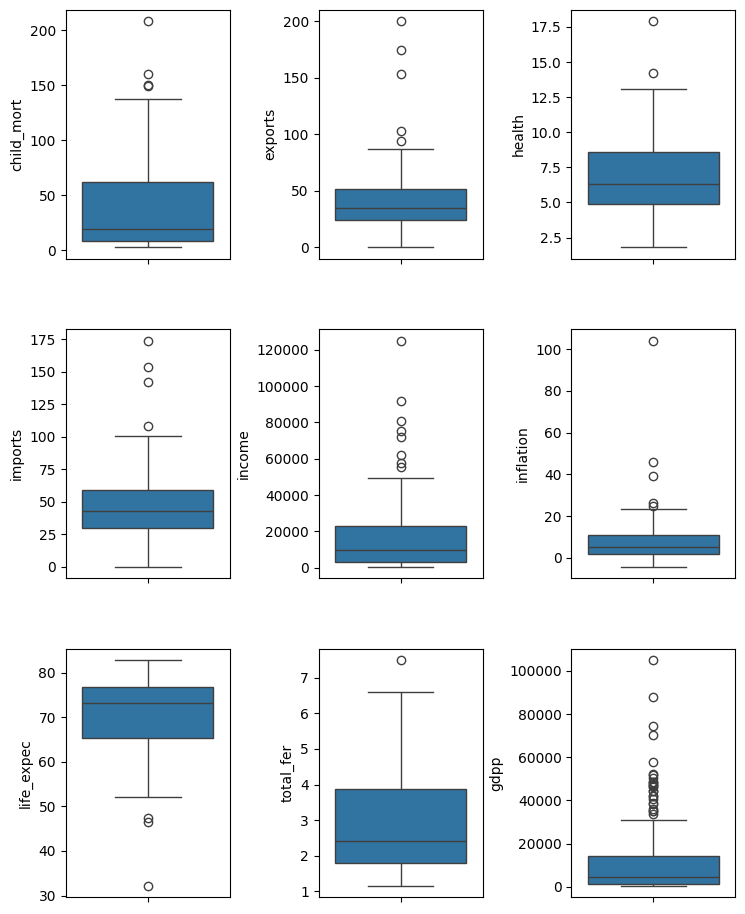

In [7]:
#Analisis de distribucion 

num_cols= df.select_dtypes(exclude= "object").columns

fig, axs = plt.subplots(3, 3, figsize=(8, 10))
plt.tight_layout(pad=3)

for i, ax in enumerate(axs.flat):
    sns.boxplot(data=df, y=num_cols[i], ax=ax)

<Axes: >

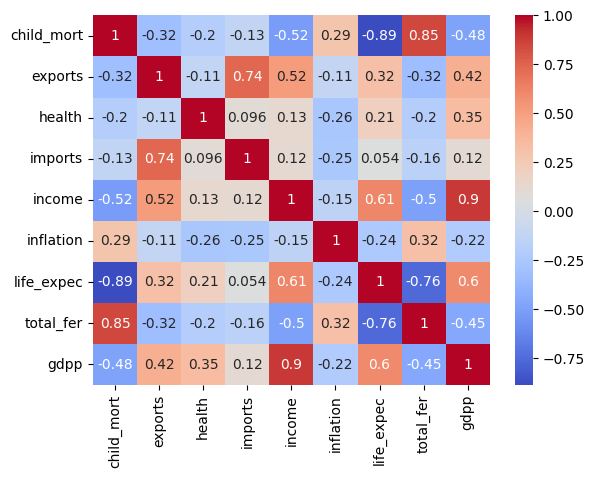

In [8]:
sns.heatmap(df[num_cols].corr(), annot= True, cmap= "coolwarm")

In [9]:
#Escalar los datos 
from sklearn.preprocessing import StandardScaler

scaler= StandardScaler()
df_scaled= scaler.fit_transform(df.drop("country", axis=1)) 
df_scaled= pd.DataFrame(df_scaled, columns= df.drop("country", axis=1).columns)

PCA

In [10]:
from sklearn.decomposition import PCA

pca= PCA()
pca.fit(df_scaled)
pca_df_scaled= pca.transform(df_scaled) 

[0.4595174  0.17181626 0.13004259 0.11053162 0.07340211 0.02484235
 0.0126043  0.00981282 0.00743056]


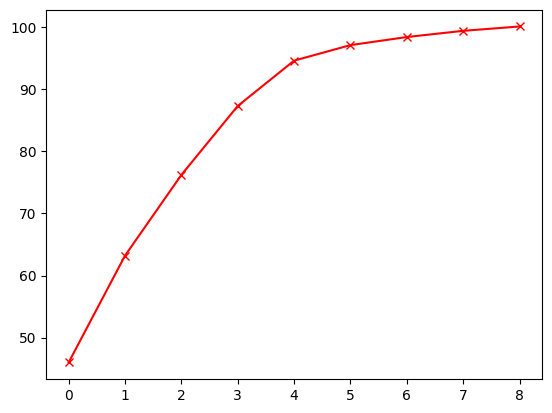

In [11]:
var= pca.explained_variance_ratio_
print(var)

acum_var= np.cumsum(np.round(var,3)*100)
plt.plot(acum_var, "r-x")

In [12]:
pca_df_standard= pd.DataFrame(pca_df_scaled)
pca_df_standard.drop([4,5,6,7,8], axis=1, inplace= True)
pca_df_standard

,0,1,2,3
0,-2.913025,0.095621,-0.718118,1.005255
1,0.429911,-0.588156,-0.333486,-1.161059
2,-0.285225,-0.455174,1.221505,-0.868115
3,-2.932423,1.695555,1.525044,0.839625
4,1.033576,0.136659,-0.225721,-0.847063
...,...,...,...,...
162,-0.820631,0.639570,-0.389923,-0.706595
163,-0.551036,-1.233886,3.101350,-0.115311
164,0.498524,1.390744,-0.238526,-1.074098
165,-1.887451,-0.109453,1.109752,0.056257


PROBANDO DISTINTOS ALGORITMOS DE AGRUPACION 

KMEANS

In [15]:
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

In [19]:
sum_squared_distances= []
silhouette_scores= []
K= range(2,15)

for i in K:
    km= KMeans(n_clusters= i)
    y= km.fit_predict(pca_df_standard)
    sum_squared_distances.append(km.inertia_)
    silhouette_scores.append(silhouette_score(pca_df_standard, y))

Text(0, 0.5, 'Inertia')

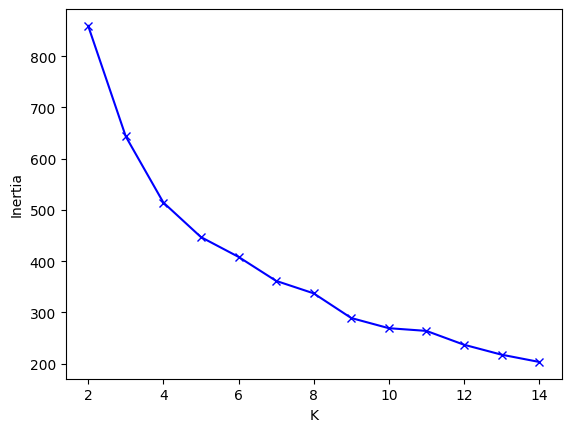

In [20]:
plt.plot(K, sum_squared_distances, "bx-")
plt.xlabel("K")
plt.ylabel("Inertia")

Text(0, 0.5, 'silhouette score')

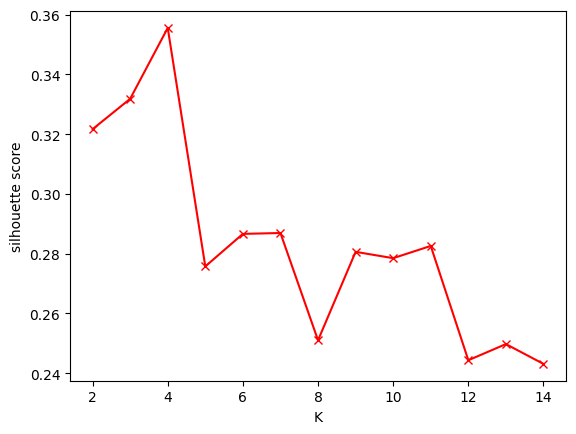

In [21]:
plt.plot(K, silhouette_scores, "rx-")
plt.xlabel("K")
plt.ylabel("silhouette score")

In [22]:
km= KMeans(n_clusters= 4)
y= km.fit_predict(pca_df_standard)
print(silhouette_score(pca_df_standard, y))
df["kmeans_pca"]= y

0.3352960060223144


KMEANS SIN PCA

In [23]:
sum_squared_distances= []
silhouette_scores= []
K= range(2,15)

for i in K:
    km= KMeans(n_clusters= i)
    y= km.fit_predict(df_scaled)
    sum_squared_distances.append(km.inertia_)
    silhouette_scores.append(silhouette_score(df_scaled, y))

Text(0, 0.5, 'Inertia')

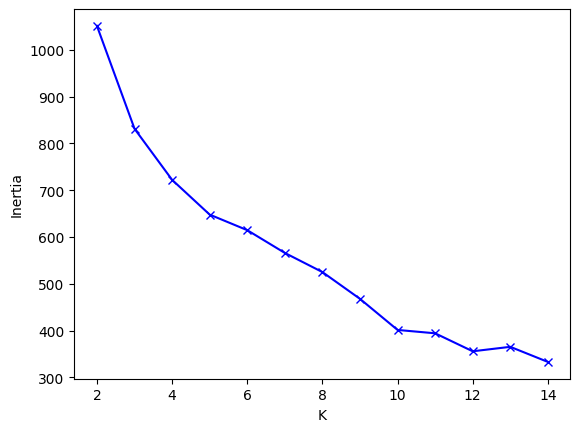

In [24]:
plt.plot(K, sum_squared_distances, "bx-")
plt.xlabel("K")
plt.ylabel("Inertia")

Text(0, 0.5, 'silhouette score')

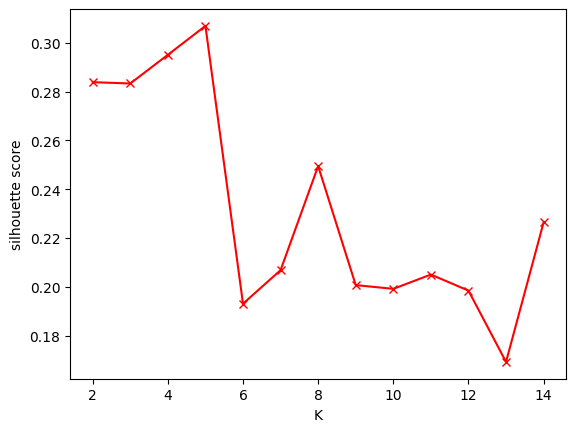

In [25]:
plt.plot(K, silhouette_scores, "rx-")
plt.xlabel("K")
plt.ylabel("silhouette score")

In [26]:
km= KMeans(n_clusters= 5)
y= km.fit_predict(df_scaled)
print(silhouette_score(df_scaled, y))
df["kmeans"]= y

0.29991582681104606


HIERARCHICAL CLUSTERING

Text(0, 0.5, 'Euclidean distance')

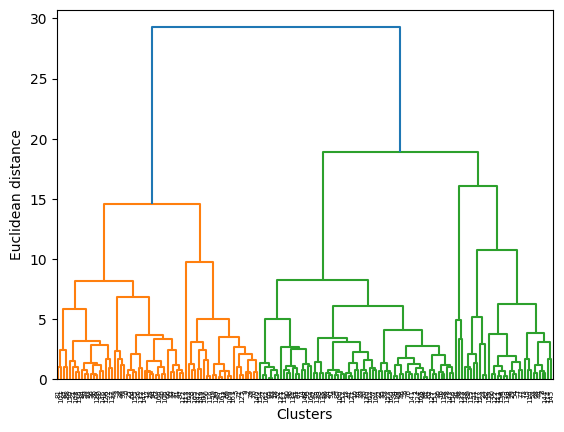

In [27]:
dendrogram_plot= dendrogram(linkage(pca_df_standard, method= "ward"))
plt.xlabel("Clusters")
plt.ylabel("Euclidean distance")

In [30]:
hc= AgglomerativeClustering(n_clusters= 2, metric= "euclidean", linkage= "ward")
y_hc= hc.fit_predict(pca_df_standard)
print(silhouette_score(pca_df_standard, y_hc))
df["hc_pca"]= y_hc

0.3070110704080526


HIERARCHICAL CLUSTERING SIN PCA

Text(0, 0.5, 'Euclidean distance')

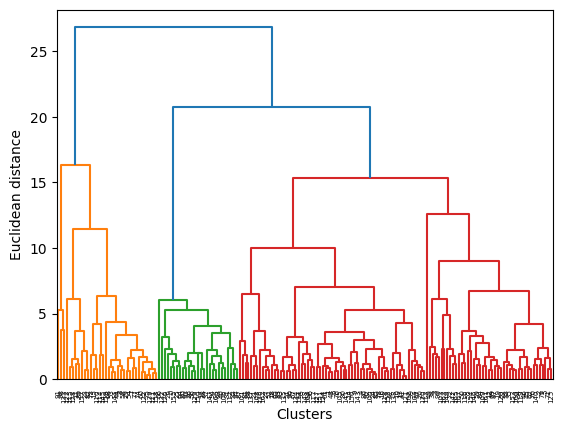

In [31]:
dendrogram_plot= dendrogram(linkage(df_scaled, method= "ward"))
plt.xlabel("Clusters")
plt.ylabel("Euclidean distance")

In [34]:
hc= AgglomerativeClustering(n_clusters= 2, metric= "euclidean", linkage= "ward")
y_hc= hc.fit_predict(df_scaled)
print(silhouette_score(df_scaled, y_hc))
df["hc"]= y_hc

0.3153134331018189


DBSCAN

In [42]:
from sklearn.neighbors import NearestNeighbors

neighbors= NearestNeighbors(n_neighbors=2)
neighbors_fit= neighbors.fit(pca_df_standard)
distances, indices= neighbors_fit.kneighbors(pca_df_standard)

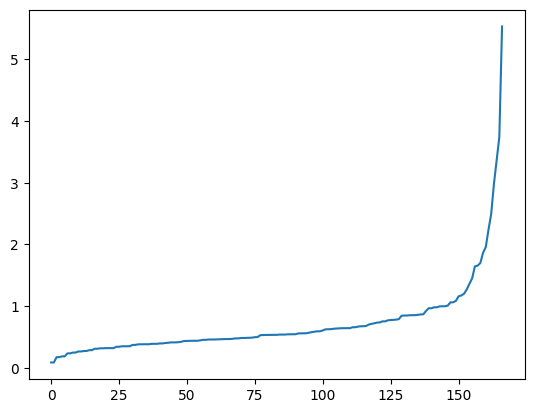

In [44]:
distances= np.sort(distances, axis=0)
distances= distances[:,1]
plt.plot(distances)

In [46]:
eps_values= np.arange(0.5, 2, 0.1)
min_sample= np.arange(3,12)

In [57]:
from itertools import product

dbscan_params= list(product(eps_values, min_sample)) 
n_of_clusters= []
sil_score= [] 

for i in dbscan_params:
    y_dbscan= DBSCAN(eps= i[0], min_samples= i[1]).fit_predict(pca_df_standard)
    try:
        sil_score.append(silhouette_score(pca_df_standard, y_dbscan))
        
    except:
        sil_score.append(0)
    n_of_clusters.append(len(np.unique(y_dbscan)))

In [59]:
df_params_tunning= pd.DataFrame.from_records(dbscan_params, columns=["Eps", "Min_samples"])
df_params_tunning["sil_score"]= sil_score 
df_params_tunning["n_of_clusters"]= n_of_clusters

In [60]:
pivot_1= pd.pivot_table(df_params_tunning, values= "sil_score", columns= "Eps", index= "Min_samples")
pivot_2= pd.pivot_table(df_params_tunning, values= "n_of_clusters", columns= "Eps", index= "Min_samples")

<Axes: xlabel='Eps', ylabel='Min_samples'>

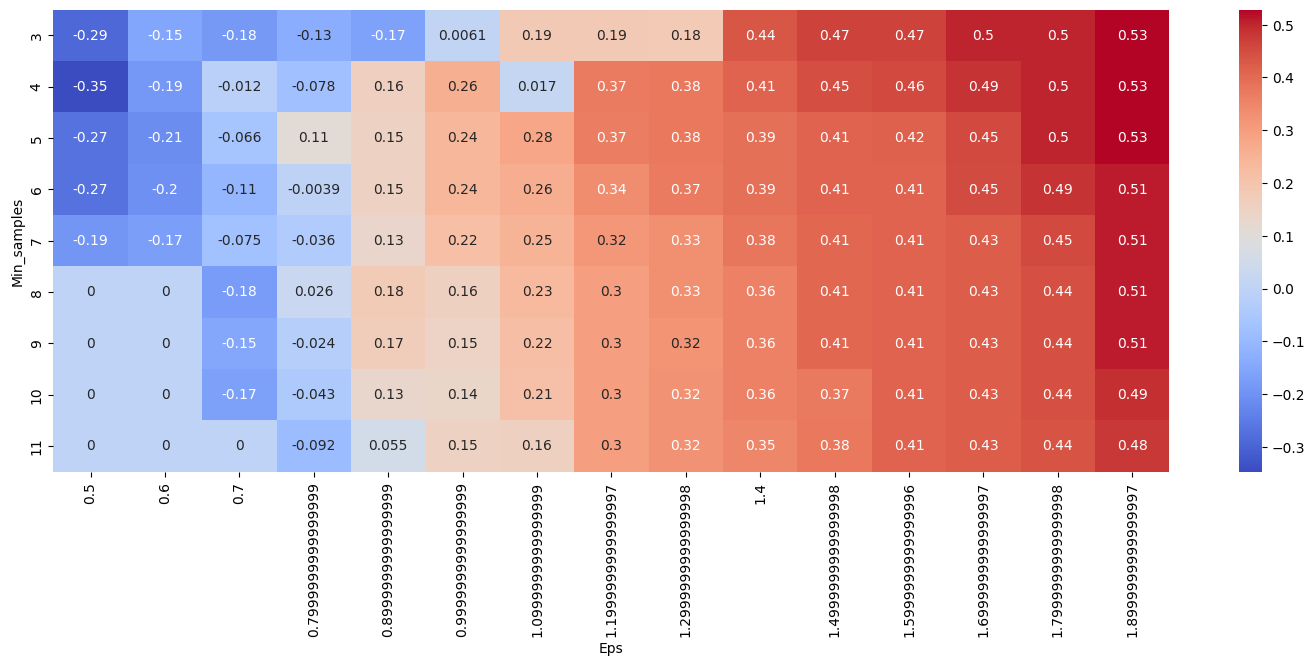

In [55]:
plt.figure(figsize= (18,6))
sns.heatmap(pivot_1, annot= True, cmap="coolwarm")

<Axes: xlabel='Eps', ylabel='Min_samples'>

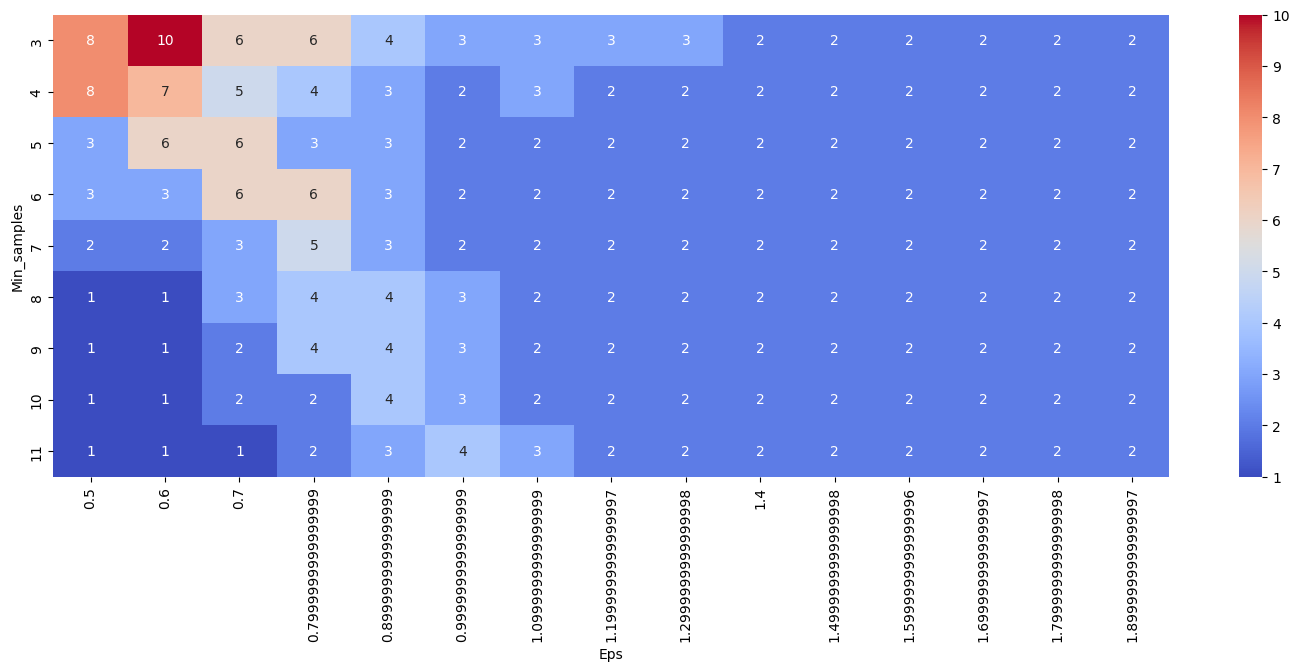

In [61]:
plt.figure(figsize= (18,6))
sns.heatmap(pivot_2, annot= True, cmap="coolwarm")

In [63]:
#Pese a que hay combinaciones que logran mejores silhouette score, estos retornan un numero de clusters muy bajo. La idea es tomar al menos 3 clusters
#y lograr el mayor silhouette score posible

dbscan_train= DBSCAN(eps= 1.2, min_samples= 3)
y_dbscan= dbscan_train.fit_predict(pca_df_standard)
print(silhouette_score(pca_df_standard, y_dbscan))
df["dbscan_pca"]= y_dbscan

0.1859117573078435


DBSCAN SIN PCA

In [64]:
neighbors= NearestNeighbors(n_neighbors=2)
neighbors_fit= neighbors.fit(df_scaled)
distances, indices= neighbors_fit.kneighbors(df_scaled)

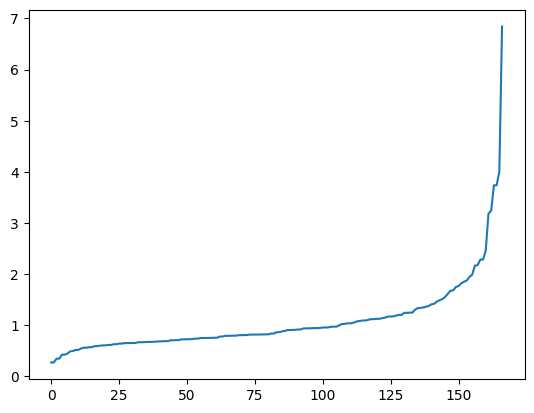

In [65]:
distances= np.sort(distances, axis=0)
distances= distances[:,1]
plt.plot(distances)

In [66]:
eps_values= np.arange(1,3, 0.1)
min_sample= np.arange(3,12)

In [67]:
dbscan_params= list(product(eps_values, min_sample)) 
n_of_clusters= []
sil_score= [] 

for i in dbscan_params:
    y_dbscan= DBSCAN(eps= i[0], min_samples= i[1]).fit_predict(df_scaled)
    try:
        sil_score.append(silhouette_score(df_scaled, y_dbscan))
        
    except:
        sil_score.append(0)
    n_of_clusters.append(len(np.unique(y_dbscan)))

In [68]:
df_params_tunning= pd.DataFrame.from_records(dbscan_params, columns=["Eps", "Min_samples"])
df_params_tunning["sil_score"]= sil_score 
df_params_tunning["n_of_clusters"]= n_of_clusters

In [69]:
pivot_1= pd.pivot_table(df_params_tunning, values= "sil_score", columns= "Eps", index= "Min_samples")
pivot_2= pd.pivot_table(df_params_tunning, values= "n_of_clusters", columns= "Eps", index= "Min_samples")

<Axes: xlabel='Eps', ylabel='Min_samples'>

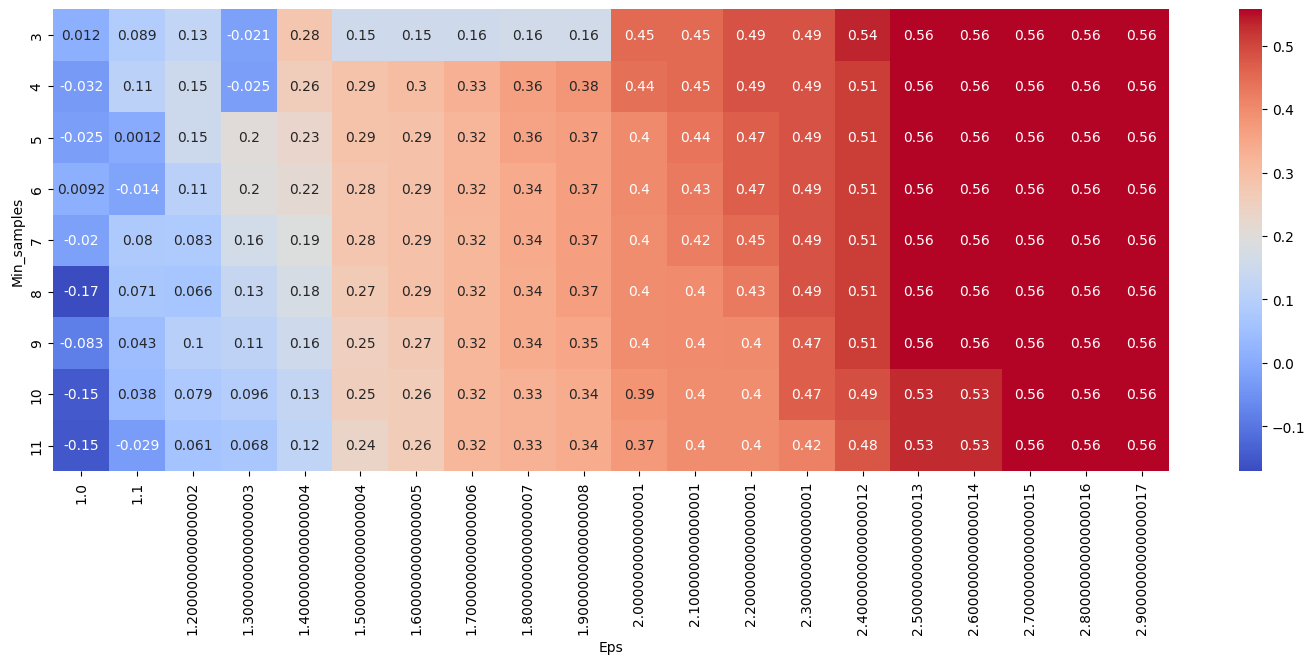

In [70]:
plt.figure(figsize= (18,6))
sns.heatmap(pivot_1, annot= True, cmap="coolwarm")

<Axes: xlabel='Eps', ylabel='Min_samples'>

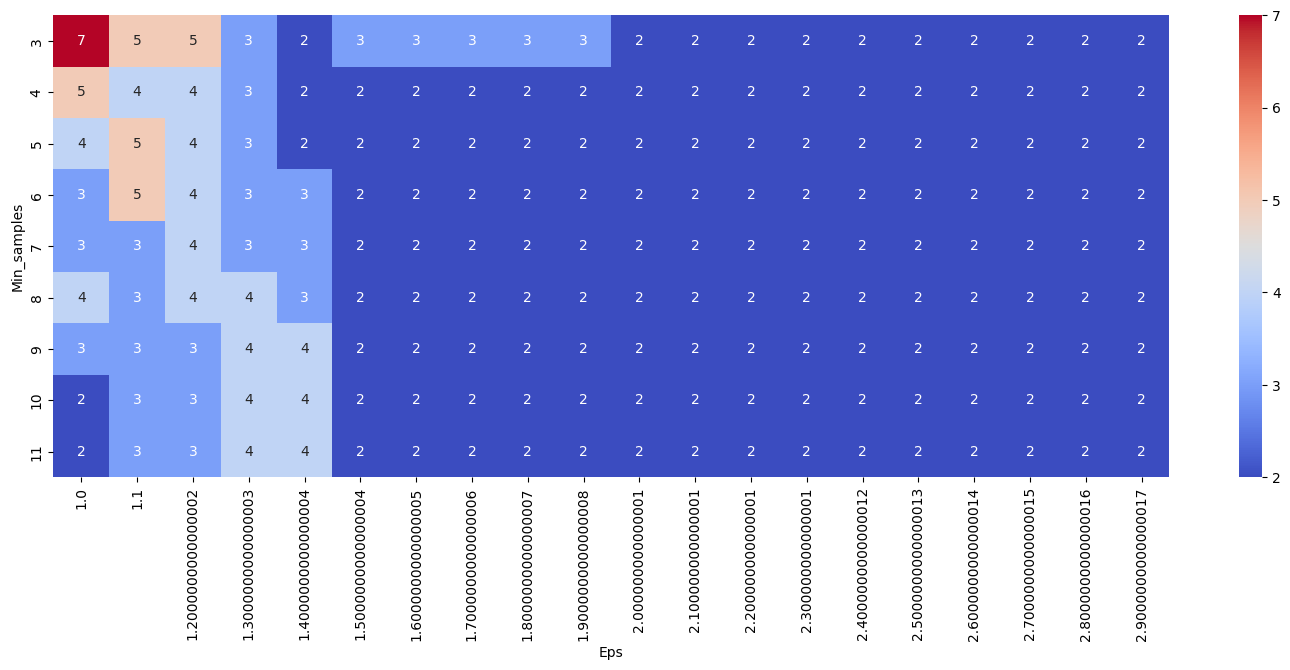

In [71]:
plt.figure(figsize= (18,6))
sns.heatmap(pivot_2, annot= True, cmap="coolwarm")

In [72]:
#Pese a que hay combinaciones que logran mejores silhouette score, estos retornan un numero de clusters muy bajo. La idea es tomar al menos 3 clusters
#y lograr el mayor silhouette score posible

dbscan_train= DBSCAN(eps= 1.7, min_samples= 3)
y_dbscan= dbscan_train.fit_predict(df_scaled)
print(silhouette_score(df_scaled, y_dbscan))
df["dbscan"]= y_dbscan

0.1563549566374231


EVALUAR LOS RESULTADOS

In [74]:
df.head()

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp,kmeans_pca,kmeans,hc_pca,hc,dbscan_pca,dbscan
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553,2,0,1,0,0,0
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090,1,1,0,0,0,0
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460,1,1,1,0,0,0
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530,2,0,1,0,-1,0
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200,1,1,0,0,0,0


In [75]:
df.columns

Index(['country', 'child_mort', 'exports', 'health', 'imports', 'income',
       'inflation', 'life_expec', 'total_fer', 'gdpp', 'kmeans_pca', 'kmeans',
       'hc_pca', 'hc', 'dbscan_pca', 'dbscan'],
      dtype='object')

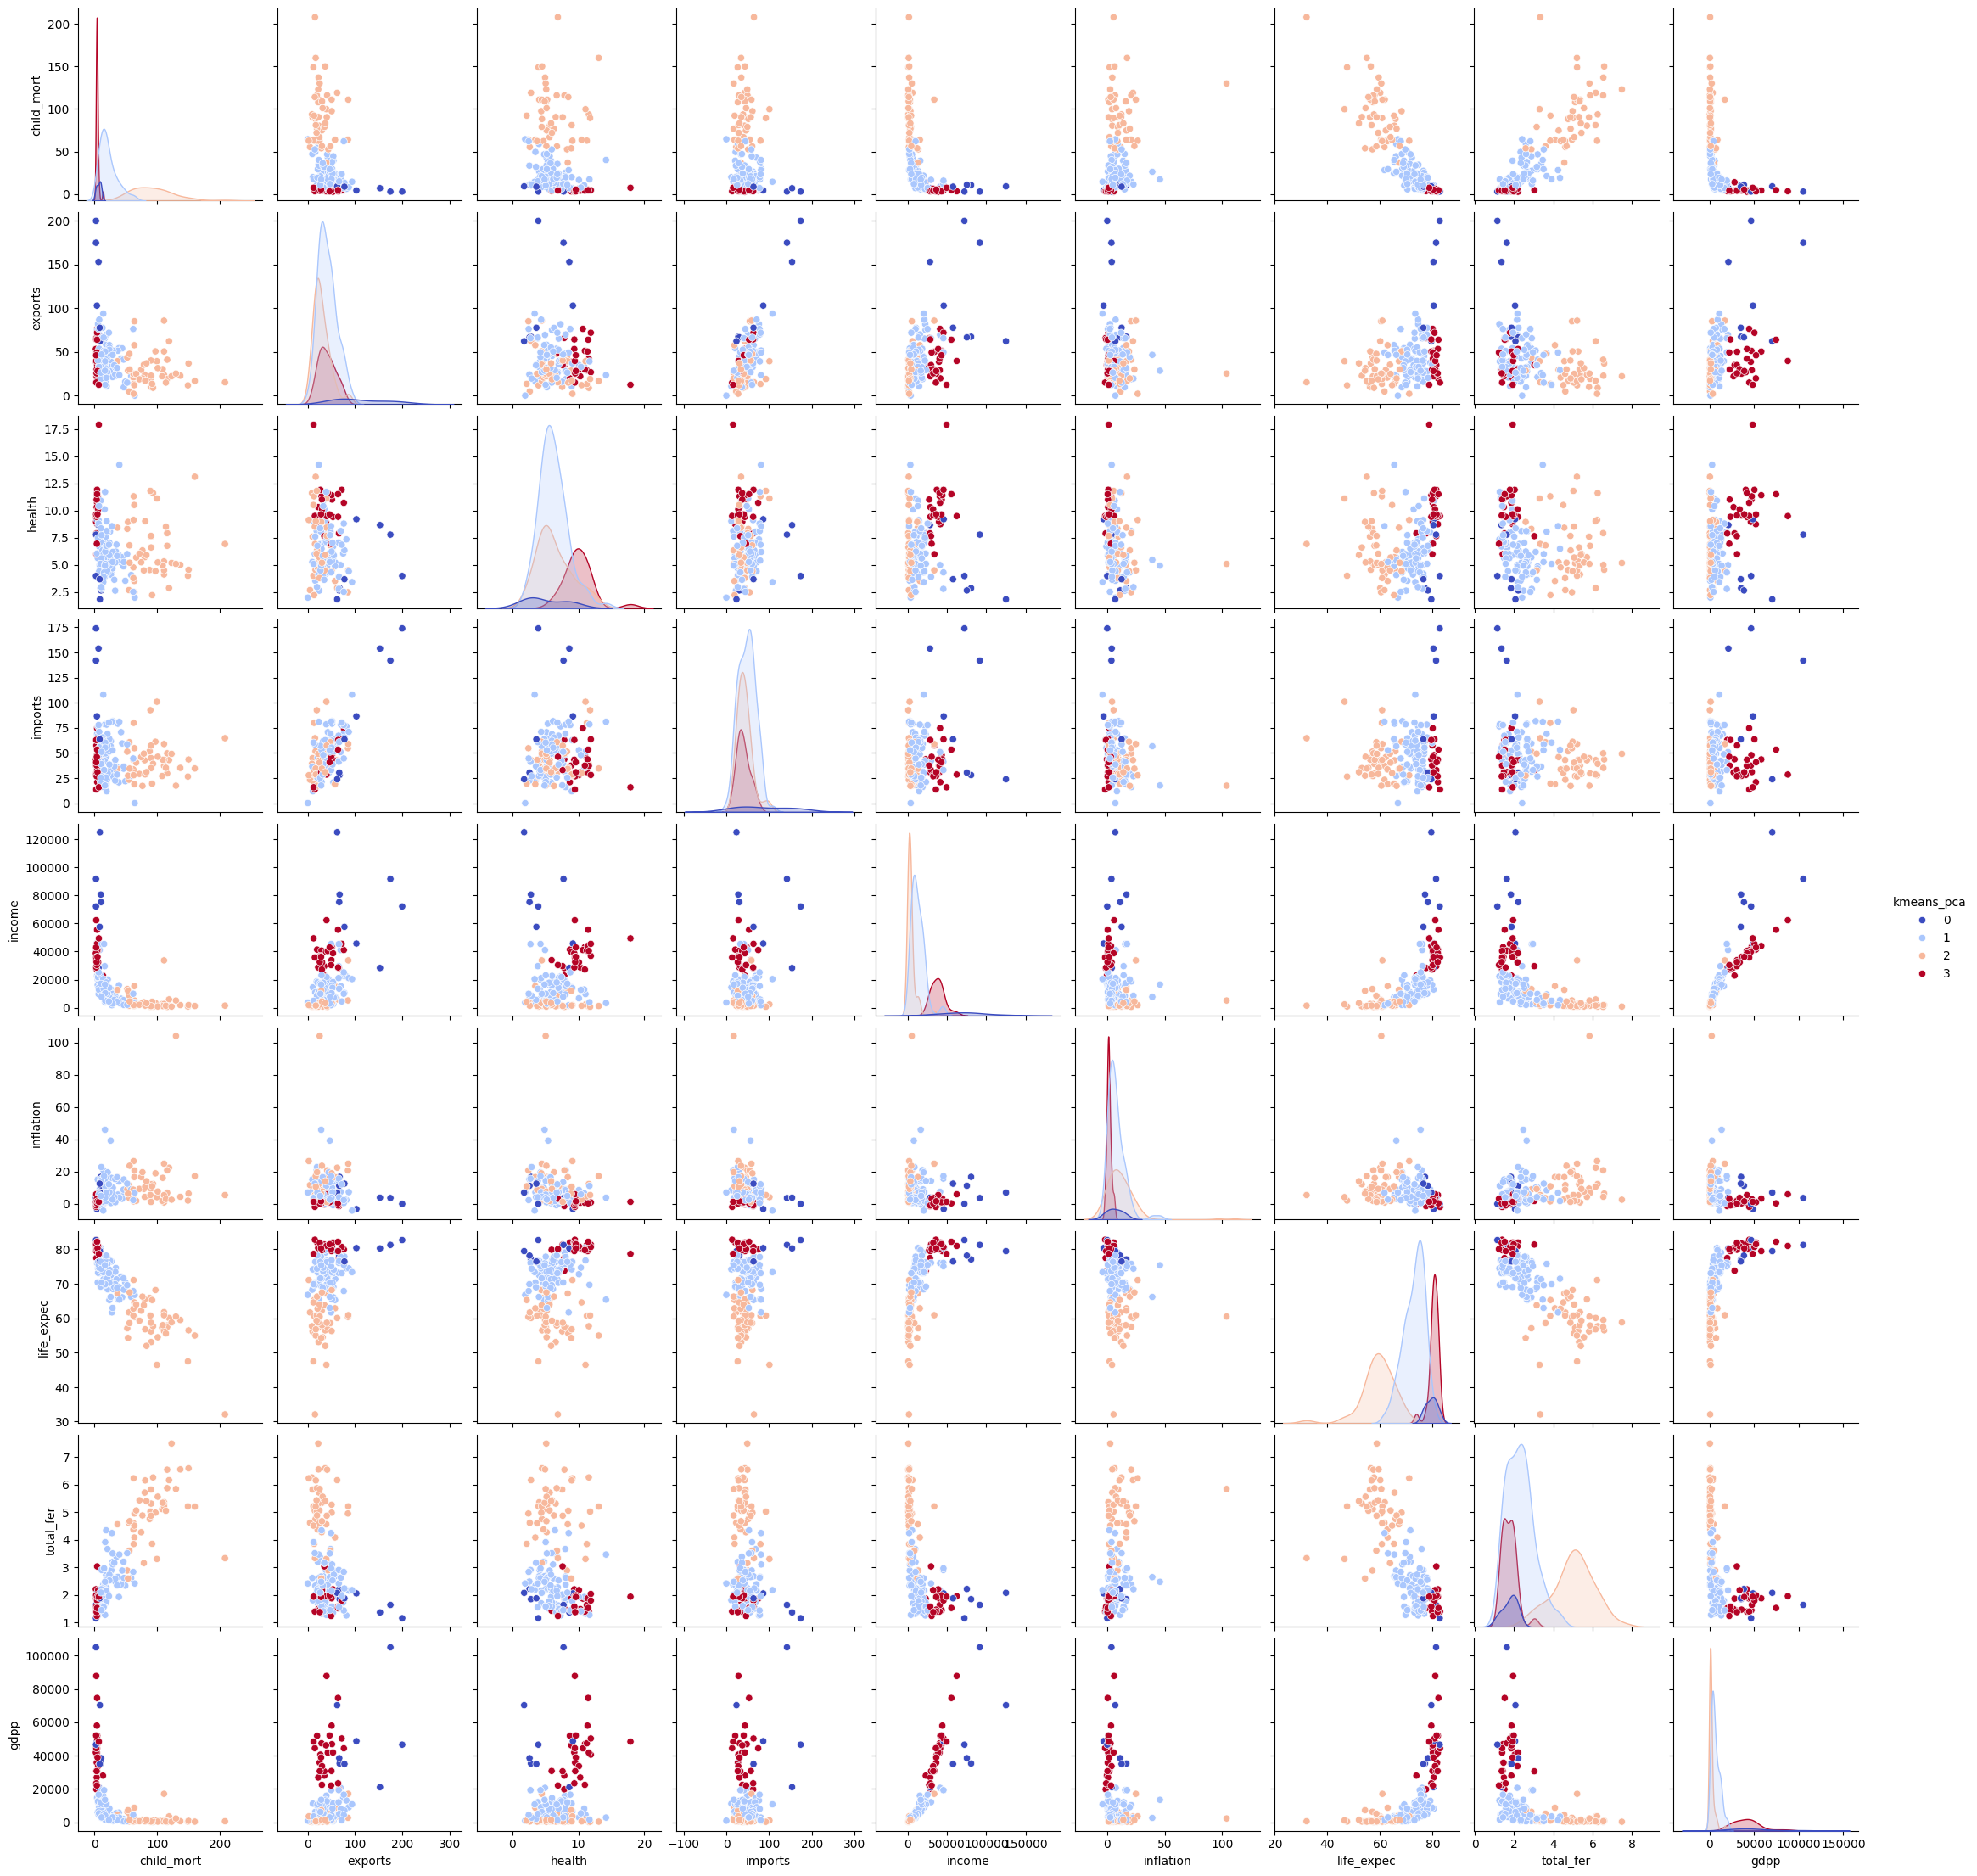

In [76]:
sns.pairplot(data= df[['child_mort', 'exports', 'health', 'imports', 'income',
       'inflation', 'life_expec', 'total_fer', 'gdpp', 'kmeans_pca']], hue= "kmeans_pca", palette= "coolwarm")

<Axes: xlabel='child_mort', ylabel='gdpp'>

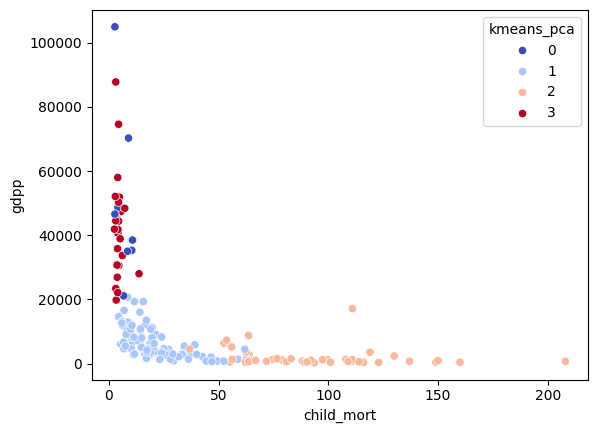

In [77]:
sns.scatterplot(data= df, x="child_mort", y= "gdpp", hue= "kmeans_pca", palette= "coolwarm")

In [82]:
df[df["kmeans_pca"]==0]

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp,kmeans_pca,kmeans,hc_pca,hc,dbscan_pca,dbscan
23,Brunei,10.5,67.4,2.84,28.0,80600,16.700,77.1,1.84,35300,0,3,0,1,-1,-1
73,Ireland,4.2,103.0,9.19,86.5,45700,-3.220,80.4,2.05,48700,0,4,0,1,0,0
82,Kuwait,10.8,66.7,2.63,30.4,75200,11.200,78.2,2.21,38500,0,3,0,1,-1,-1
91,Luxembourg,2.8,175.0,7.77,142.0,91700,3.620,81.3,1.63,105000,0,2,0,1,-1,-1
98,Malta,6.8,153.0,8.65,154.0,28300,3.830,80.3,1.36,21100,0,2,0,1,-1,-1
123,Qatar,9.0,62.3,1.81,23.8,125000,6.980,79.5,2.07,70300,0,3,0,1,-1,-1
133,Singapore,2.8,200.0,3.96,174.0,72100,-0.046,82.7,1.15,46600,0,2,0,1,-1,-1
157,United Arab Emirates,8.6,77.7,3.66,63.6,57600,12.500,76.5,1.87,35000,0,3,0,1,-1,0


In [ ]:
df.drop(['kmeans','hc_pca', 'hc', 'dbscan_pca', 'dbscan'], axis=1)

In [85]:
import pycountry
import plotly.express as px

def get_alpha_3(location):
    try:
        return pycountry.countries.get(name=location).alpha_3
    except:
        return None

df_map = df.copy()
df_map['Code'] = df['country'].apply(lambda x: get_alpha_3(x))

fig = px.choropleth(df_map, locations='Code', color='kmeans_pca', hover_name='country', color_continuous_scale=px.colors.sequential.Plasma)
fig.show()

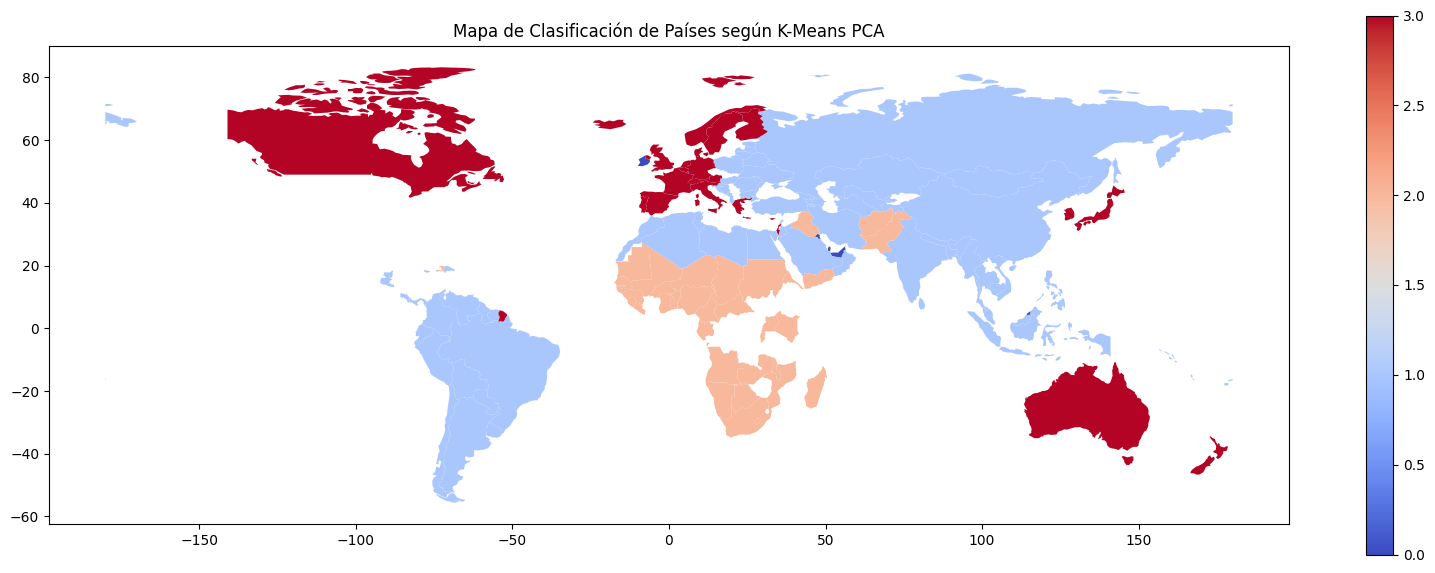

In [101]:
import geopandas as gpd
import matplotlib.pyplot as plt

# Cargar datos geoespaciales del mundo y fusionarlos con el df
world = gpd.read_file('C:/Users/SEBASTIAN/Documents/Cursos/curso_ciencia_de_datos/30_days_of_python/Clustering/ne_110m_admin_0_countries/ne_110m_admin_0_countries.shp')

Clasificacion = pd.DataFrame({'country':df.country,
                             'kmeans_pca':df.kmeans_pca})

world = world.merge(Clasificacion, how='left', left_on='ADMIN', right_on='country')

# Crear el gráfico
fig, ax = plt.subplots(1, 1, figsize=(20, 7))

world.plot(ax=ax, column='kmeans_pca', legend=True, cmap='coolwarm')

plt.title('Mapa de Clasificación de Países según K-Means PCA')

plt.show()